# Notebook 3 — Problem Solving dengan Searching: Rute Evakuasi Banjir Ciledug
**Proyek UTS Kecerdasan Artifisial: Agen Cerdas Tanggap Banjir Ciledug**

Setelah agen mengenali sebuah tweet sebagai **laporan banjir** (Notebook 2) dan mengetahui lokasinya, agen harus mencari
**rute dari lokasi laporan ke tempat aman terdekat** (rumah sakit, puskesmas, pemadam kebakaran, kantor polisi/kelurahan)
di jaringan jalan nyata, sambil **menghindari ruas jalan yang tergenang**.

Algoritma yang dibandingkan:
- **Breadth-First Search (BFS)**: uninformed, menjamin jumlah ruas (langkah) paling sedikit.
- **Depth-First Search (DFS)**: uninformed, hemat memori, tidak menjamin optimal.
- **Uniform Cost Search (UCS / Dijkstra)**: uninformed, optimal terhadap biaya; dipakai sebagai **pembanding optimalitas**.
- **A\* Search**: informed, memakai heuristik jarak garis lurus (haversine); optimal dan lebih efisien dari UCS.

In [1]:
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "osmnx"], check=True)
    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/izviopm/uts-ai-banjir-ciledug.git", "/content/repo"], check=True)
    os.chdir("/content/repo")
elif Path("../data").exists():
    os.chdir("..")

In [2]:
import heapq, json, math, random, time
from collections import deque
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

FIG = Path("laporan/gambar"); FIG.mkdir(parents=True, exist_ok=True)
EXPORT = Path("web/public/model"); EXPORT.mkdir(parents=True, exist_ok=True)
CACHE = Path("data/cache"); CACHE.mkdir(parents=True, exist_ok=True)
if "google.colab" in sys.modules:  # cache di Google Drive supaya peta tidak diunduh ulang tiap sesi
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CACHE = Path("/content/drive/MyDrive/UTS-AI-Banjir"); CACHE.mkdir(parents=True, exist_ok=True)
    except Exception as e:
        print("Drive tidak di-mount, cache lokal sesi:", e)

PUSAT = (-6.22577, 106.70457)   # Kantor Kecamatan Ciledug (Nominatim)
RADIUS = 4500                   # meter
SEED = 42

## 1. Formulasi masalah (State Space)
| Komponen | Definisi pada kasus ini |
|---|---|
| **State** | Persimpangan jalan (node graf OpenStreetMap) tempat agen/kendaraan berada |
| **Initial state** | Node terdekat dari lokasi laporan banjir (hasil ekstraksi lokasi tweet) |
| **Actions / Operators** | Bergerak dari satu persimpangan ke persimpangan tetangga melalui ruas jalan yang bisa dilalui mobil (sesuai arah jalan satu arah) |
| **Transition model** | `Result(s, a)` = persimpangan di ujung ruas jalan yang dipilih |
| **Goal test** | State adalah salah satu node **tempat aman** (RS, klinik, damkar, polisi, kantor pemerintahan) |
| **Path cost** | Σ biaya ruas; biaya = panjang ruas (meter) × **penalti genangan** (×20 bila ruas berada dalam radius titik banjir) |

Penalti ×20 (bukan menutup jalan) dipilih karena genangan 20–50 cm masih mungkin dilewati kendaraan tanggap darurat,
tetapi sangat lambat dan berisiko. Agen akan menghindarinya kecuali tidak ada alternatif, misalnya saat titik awal
sendiri berada di dalam genangan.

**Heuristik A\***: $h(n) = \min_{g \in \text{Goal}} \text{haversine}(n, g)$. Heuristik ini **admissible** karena biaya
ruas mana pun ≥ panjangnya ≥ jarak garis lurus, sehingga A\* dijamin menemukan rute berbiaya minimum.

## 2. Lingkungan: jaringan jalan Ciledug (OpenStreetMap)

In [3]:
graf_file = CACHE / "ciledug_drive.graphml"
if graf_file.exists():
    G = ox.load_graphml(graf_file)
else:
    G = ox.graph_from_point(PUSAT, dist=RADIUS, network_type="drive")
    ox.save_graphml(G, graf_file)
G = ox.truncate.largest_component(G, strongly=True)  # semua node saling terjangkau
print(f"Node (persimpangan): {G.number_of_nodes():,}  |  Edge (ruas berarah): {G.number_of_edges():,}")

Node (persimpangan): 19,066  |  Edge (ruas berarah): 43,861


### Titik rawan banjir
Sumber: daftar genangan BPBD Kota Tangerang yang diberitakan
[IDN Times, 20 Feb 2026](https://banten.idntimes.com/news/banten/21-titik-di-8-kecamatan-di-kota-tangerang-tergenang-banjir-c1c2-01-h9ml6-glx88x)
dan [Liputan6, 4 Mar 2025](https://www.liputan6.com/news/read/5944273/banjir-melanda-perumahan-ciledug-indah-kota-tangerang-ketinggian-air-30-50-cm).
Koordinat dari geocoding Nominatim (OpenStreetMap). Dua lokasi di berita (Komplek Patal dan Jl. H. Mean) tidak ditemukan di
OpenStreetMap sehingga tidak dipetakan. "Kreo" hanya tersedia sebagai titik tengah kelurahan, jadi radiusnya dibuat lebih besar.

In [4]:
SUMBER_IDN = "https://banten.idntimes.com/news/banten/21-titik-di-8-kecamatan-di-kota-tangerang-tergenang-banjir-c1c2-01-h9ml6-glx88x"
SUMBER_L6 = "https://www.liputan6.com/news/read/5944273/banjir-melanda-perumahan-ciledug-indah-kota-tangerang-ketinggian-air-30-50-cm"
banjir = pd.DataFrame([
    ("Perumahan Ciledug Indah", -6.21940, 106.69836, 250, SUMBER_L6),
    ("Komplek Puri Kartika, Tajur", -6.24347, 106.69792, 200, SUMBER_IDN),
    ("Komplek Griya Kencana", -6.22567, 106.69815, 200, SUMBER_IDN),
    ("Komplek Taman Asri, Cipadu", -6.23699, 106.73324, 200, SUMBER_IDN),
    ("Kreo, Larangan", -6.23006, 106.73987, 300, SUMBER_IDN),
    ("Jalan Inpres Raya, Gaga", -6.24212, 106.72154, 150, SUMBER_IDN),
    ("Jalan Raden Saleh Raya, Karang Mulya", -6.19134, 106.72410, 150, SUMBER_IDN),
], columns=["name", "lat", "lon", "radius_m", "source_url"])
banjir

,name,lat,lon,radius_m,source_url
0,Perumahan Ciledug Indah,-6.21940,106.69836,250,https://www.liputan6.com/news/read/5944273/ban...
1,"Komplek Puri Kartika, Tajur",-6.24347,106.69792,200,https://banten.idntimes.com/news/banten/21-tit...
2,Komplek Griya Kencana,-6.22567,106.69815,200,https://banten.idntimes.com/news/banten/21-tit...
3,"Komplek Taman Asri, Cipadu",-6.23699,106.73324,200,https://banten.idntimes.com/news/banten/21-tit...
4,"Kreo, Larangan",-6.23006,106.73987,300,https://banten.idntimes.com/news/banten/21-tit...
5,"Jalan Inpres Raya, Gaga",-6.24212,106.72154,150,https://banten.idntimes.com/news/banten/21-tit...
6,"Jalan Raden Saleh Raya, Karang Mulya",-6.19134,106.72410,150,https://banten.idntimes.com/news/banten/21-tit...


In [5]:
def haversine(lat1, lon1, lat2, lon2):
    """Jarak garis lurus di permukaan bumi (meter). Mendukung numpy array."""
    R = 6_371_000
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2) - np.radians(lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def hav(lat1, lon1, lat2, lon2):
    """Versi skalar (math) untuk heuristik A*: jauh lebih cepat dari numpy untuk satu pasangan titik."""
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 12_742_000 * math.asin(math.sqrt(a))

LAT = {n: d["y"] for n, d in G.nodes(data=True)}
LON = {n: d["x"] for n, d in G.nodes(data=True)}

def tergenang(u, v):
    mlat, mlon = (LAT[u] + LAT[v]) / 2, (LON[u] + LON[v]) / 2
    return bool((haversine(mlat, mlon, banjir.lat.values, banjir.lon.values) <= banjir.radius_m.values).any())

from matplotlib.collections import LineCollection

def gambar_jalan(ax, tandai_genangan=True):
    """Gambar seluruh ruas sekaligus (LineCollection), jauh lebih cepat dari ax.plot per ruas."""
    biasa = [[(LON[u], LAT[u]), (LON[v], LAT[v])] for u, nbs in adj.items() for v, _, f in nbs if not (f and tandai_genangan)]
    genang = [[(LON[u], LAT[u]), (LON[v], LAT[v])] for u, nbs in adj.items() for v, _, f in nbs if f and tandai_genangan]
    ax.add_collection(LineCollection(biasa, colors="#d0d0d0", linewidths=0.4, zorder=1))
    ax.add_collection(LineCollection(genang, colors="#1f77b4", linewidths=1.8, zorder=1, label="ruas tergenang"))
    ax.autoscale_view()

PENALTI = 20
# Daftar ketetanggaan: {u: [(v, panjang_m, tergenang)]}, ambil ruas terpendek jika ada ruas paralel
adj = {n: {} for n in G.nodes}
for u, v, d in G.edges(data=True):
    if v not in adj[u] or d["length"] < adj[u][v][0]:
        adj[u][v] = (d["length"], tergenang(u, v))
adj = {u: sorted((v, L, f) for v, (L, f) in nb.items()) for u, nb in adj.items()}
n_genang = sum(f for nb in adj.values() for _, _, f in nb)
print(f"Ruas tergenang: {n_genang} dari {sum(map(len, adj.values()))} ruas")

Ruas tergenang: 717 dari 43689 ruas


### Tempat aman (goal) dari OpenStreetMap

In [6]:
tags = {"amenity": ["hospital", "clinic", "fire_station", "police", "townhall"], "healthcare": ["hospital", "clinic"]}
aman_file = CACHE / "ciledug_aman.json"
if aman_file.exists():
    aman = pd.read_json(aman_file)
else:
    f = ox.features_from_point(PUSAT, tags=tags, dist=RADIUS).reset_index()
    titik = f.geometry.representative_point()
    aman = pd.DataFrame({
        "osmid": f["id"].astype("int64"),
        "name": f.get("name", pd.Series([None] * len(f))).fillna("(tanpa nama)"),
        "kind": f["amenity"].fillna(f.get("healthcare")) if "healthcare" in f else f["amenity"],
        "lat": titik.y, "lon": titik.x})
    aman.to_json(aman_file, orient="records")
aman = aman.drop_duplicates("osmid")
aman["node"] = ox.distance.nearest_nodes(G, aman.lon.values, aman.lat.values)
aman["dalam_genangan"] = [bool((haversine(r.lat, r.lon, banjir.lat.values, banjir.lon.values) <= banjir.radius_m.values).any())
                          for r in aman.itertuples()]
aman = aman[~aman.dalam_genangan].reset_index(drop=True)
print(aman.kind.value_counts())
aman.head(10)

kind
clinic          28
hospital        19
police          10
townhall         6
fire_station     2
Name: count, dtype: int64


,osmid,name,kind,lat,lon,node,dalam_genangan
0,4245882810,RS Mutiara Bunda Ciledug,hospital,-6.230703,106.720953,4585060145,False
1,4910065575,Posyandu Kamboja,clinic,-6.221222,106.727106,357775441,False
2,5344067751,KlinikDK Ceger Pondok Aren,hospital,-6.262817,106.733917,5447488698,False
3,6648873110,Polsubsektor Metro Permata,police,-6.204105,106.714285,4294586896,False
4,6648873111,Laboratorium Klinik Prodia,clinic,-6.204171,106.714052,4294586896,False
5,6738342382,Erha,clinic,-6.189045,106.739056,343337170,False
6,9731891369,Mandaya Royal Hospital Puri,hospital,-6.198430,106.704171,4295053492,False
7,9797112704,Bidan Ana,clinic,-6.200506,106.707537,11953275380,False
8,9824298950,Puskesmas Ciledug,hospital,-6.227885,106.704603,5488015036,False
9,11878642606,(tanpa nama),hospital,-6.194663,106.736305,343344971,False


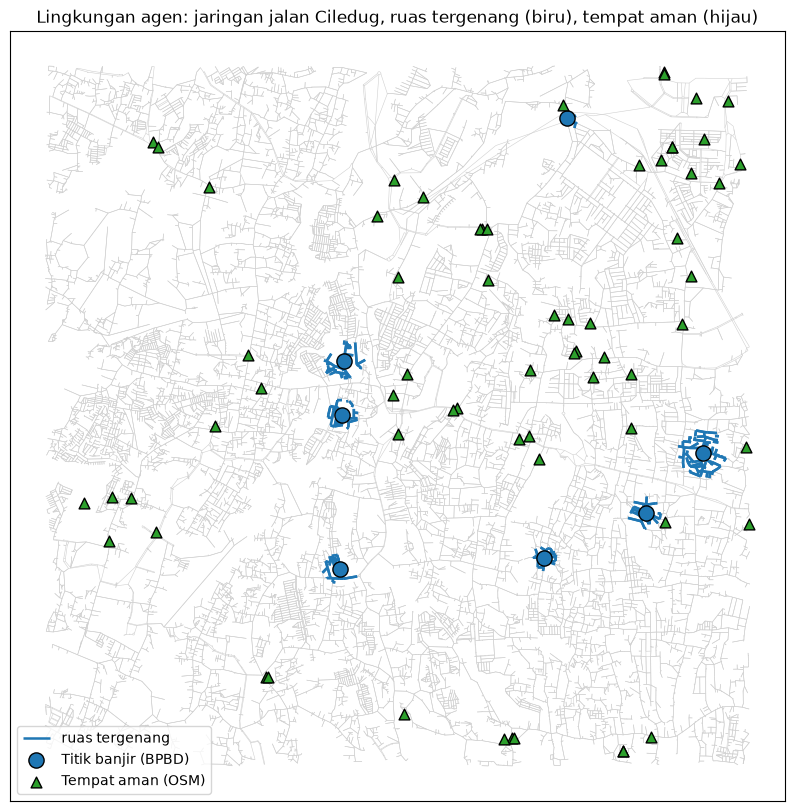

In [7]:
GOAL_AMAN = set(aman.node)
banjir["node"] = ox.distance.nearest_nodes(G, banjir.lon.values, banjir.lat.values)

fig, ax = plt.subplots(figsize=(10, 10))
gambar_jalan(ax)
ax.scatter(banjir.lon, banjir.lat, s=120, c="#1f77b4", marker="o", edgecolor="k", zorder=5, label="Titik banjir (BPBD)")
ax.scatter(aman.lon, aman.lat, s=60, c="#2ca02c", marker="^", edgecolor="k", zorder=5, label="Tempat aman (OSM)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
ax.legend(loc="lower left"); ax.set_title("Lingkungan agen: jaringan jalan Ciledug, ruas tergenang (biru), tempat aman (hijau)")
plt.savefig(FIG / "03_peta_lingkungan.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Implementasi algoritma searching
Semua algoritma ditulis manual (tanpa `networkx.shortest_path`) agar jumlah **node yang di-expand** bisa dihitung.
Mendukung banyak goal: pencarian berhenti saat menemukan tempat aman mana pun.

In [8]:
@dataclass
class Hasil:
    algoritma: str
    path: list
    expanded: int
    runtime_ms: float
    biaya: float = 0.0
    jarak_m: float = 0.0

def biaya_ruas(L, f, banjir_aktif):
    return L * (PENALTI if (f and banjir_aktif) else 1)

def susun(parent, goal):
    path = [goal]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]

def hitung(path, banjir_aktif):
    biaya = jarak = 0.0
    for u, v in zip(path, path[1:]):
        L, f = next((L, f) for w, L, f in adj[u] if w == v)
        jarak += L; biaya += biaya_ruas(L, f, banjir_aktif)
    return biaya, jarak

def bfs(start, goals, banjir_aktif=True, jejak=None):
    t0 = time.perf_counter()
    frontier, parent, expanded = deque([start]), {start: None}, 0
    while frontier:
        u = frontier.popleft(); expanded += 1
        if jejak is not None: jejak.append(u)
        if u in goals:
            p = susun(parent, u)
            return Hasil("BFS", p, expanded, (time.perf_counter() - t0) * 1000, *hitung(p, banjir_aktif))
        for v, _, _ in adj[u]:
            if v not in parent:
                parent[v] = u; frontier.append(v)

def dfs(start, goals, banjir_aktif=True, jejak=None):
    t0 = time.perf_counter()
    stack, parent, visited, expanded = [start], {start: None}, set(), 0
    while stack:
        u = stack.pop()
        if u in visited:
            continue
        visited.add(u); expanded += 1
        if jejak is not None: jejak.append(u)
        if u in goals:
            p = susun(parent, u)
            return Hasil("DFS", p, expanded, (time.perf_counter() - t0) * 1000, *hitung(p, banjir_aktif))
        for v, _, _ in reversed(adj[u]):
            if v not in visited:
                parent[v] = u; stack.append(v)

def best_first(start, goals, banjir_aktif=True, heuristik=True, jejak=None):
    """UCS jika heuristik=False, A* jika heuristik=True."""
    t0 = time.perf_counter()
    gpos = [(LAT[g], LON[g]) for g in goals]
    def h(n):
        return min(hav(LAT[n], LON[n], la, lo) for la, lo in gpos) if heuristik else 0.0
    g, parent, closed, expanded = {start: 0.0}, {start: None}, set(), 0
    heap, k = [(h(start), 0, start)], 1
    while heap:
        _, _, u = heapq.heappop(heap)
        if u in closed:
            continue
        closed.add(u); expanded += 1
        if jejak is not None: jejak.append(u)
        if u in goals:
            p = susun(parent, u)
            return Hasil("A*" if heuristik else "UCS", p, expanded, (time.perf_counter() - t0) * 1000, *hitung(p, banjir_aktif))
        for v, L, f in adj[u]:
            ng = g[u] + biaya_ruas(L, f, banjir_aktif)
            if ng < g.get(v, math.inf):
                g[v] = ng; parent[v] = u
                heapq.heappush(heap, (ng + h(v), k, v)); k += 1

def ucs(s, gs, banjir_aktif=True, jejak=None):   return best_first(s, gs, banjir_aktif, False, jejak)
def astar(s, gs, banjir_aktif=True, jejak=None): return best_first(s, gs, banjir_aktif, True, jejak)
ALGO = {"BFS": bfs, "DFS": dfs, "UCS": ucs, "A*": astar}

### Validasi kebenaran
Biaya A\* dan UCS harus sama dengan biaya rute terpendek `networkx` (Dijkstra pustaka) untuk pasangan acak.

In [9]:
H = nx.DiGraph()
for u, nbs in adj.items():
    for v, L, f in nbs:
        H.add_edge(u, v, w=biaya_ruas(L, f, True))
rng = random.Random(SEED); nodes = list(adj)
for _ in range(20):
    s, t = rng.sample(nodes, 2)
    ref = nx.shortest_path_length(H, s, t, weight="w")
    assert abs(astar(s, {t}).biaya - ref) < 1e-6 and abs(ucs(s, {t}).biaya - ref) < 1e-6
print("✓ A* dan UCS menghasilkan biaya optimal yang sama dengan networkx pada 20 pasangan acak")

✓ A* dan UCS menghasilkan biaya optimal yang sama dengan networkx pada 20 pasangan acak


## 4. Studi kasus
Dari 7 titik laporan, dipilih titik yang rute A*-nya **paling berubah** ketika informasi genangan dipakai,
untuk menunjukkan nilai tambah agen yang "sadar banjir".

In [10]:
def jalankan(start, banjir_aktif):
    return {nama: f(start, GOAL_AMAN, banjir_aktif) for nama, f in ALGO.items()}

selisih = {b.name: astar(int(b.node), GOAL_AMAN, True).jarak_m - astar(int(b.node), GOAL_AMAN, False).jarak_m
           for b in banjir.itertuples()}
print({k: round(v) for k, v in selisih.items()})
asal_kasus = max(selisih, key=selisih.get)
start = int(banjir.set_index("name").node[asal_kasus])
print("Studi kasus:", asal_kasus)
kasus = {sk: jalankan(start, sk == "banjir") for sk in ["normal", "banjir"]}
nama_aman = dict(zip(aman.node, aman.name))
rows = [{"skenario": sk, "algoritma": n, "tujuan": nama_aman.get(r.path[-1]), "jarak_m": round(r.jarak_m),
         "biaya": round(r.biaya), "node_expanded": r.expanded, "langkah": len(r.path) - 1, "runtime_ms": round(r.runtime_ms, 2)}
        for sk, hs in kasus.items() for n, r in hs.items()]
pd.DataFrame(rows)

{'Perumahan Ciledug Indah': 0, 'Komplek Puri Kartika, Tajur': 431, 'Komplek Griya Kencana': 332, 'Komplek Taman Asri, Cipadu': 0, 'Kreo, Larangan': 0, 'Jalan Inpres Raya, Gaga': 0, 'Jalan Raden Saleh Raya, Karang Mulya': 1505}
Studi kasus: Jalan Raden Saleh Raya, Karang Mulya


,skenario,algoritma,tujuan,jarak_m,biaya,node_expanded,langkah,runtime_ms
0,normal,BFS,Puskesmas Kembangan Selatan,228,228,8,2,0.01
1,normal,DFS,Polsubsektor Puri Indah,13067,13067,232,162,0.23
2,normal,UCS,Puskesmas Kembangan Selatan,228,228,11,2,0.09
3,normal,A*,Puskesmas Kembangan Selatan,228,228,4,2,0.31
4,banjir,BFS,Puskesmas Kembangan Selatan,228,4180,8,2,0.01
5,banjir,DFS,Polsubsektor Puri Indah,13067,13067,232,162,0.19
6,banjir,UCS,Klinik Budhi Medika,1732,1732,299,20,0.42
7,banjir,A*,Klinik Budhi Medika,1732,1732,109,20,5.48


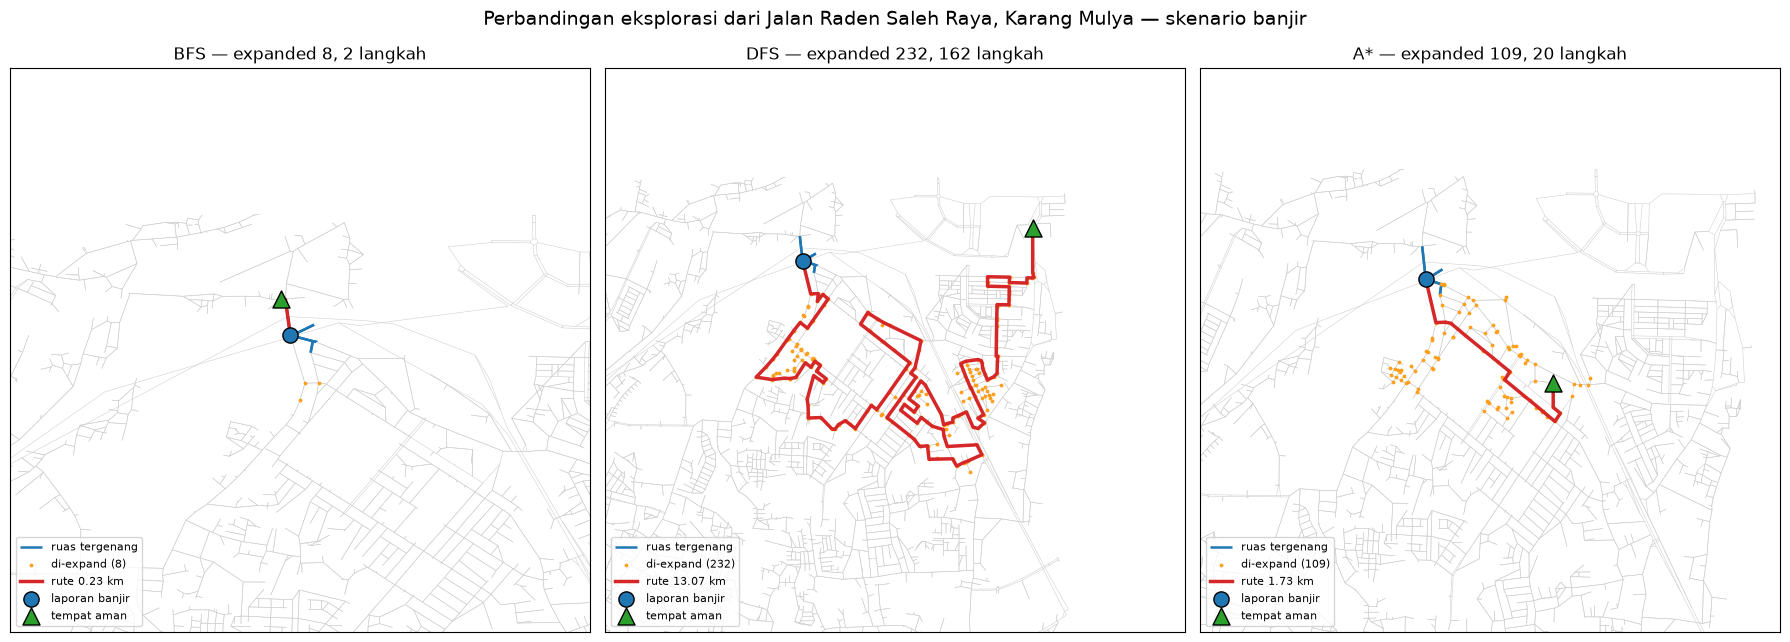

In [11]:
def gambar_eksplorasi(start, skenario, nama_file):
    hs = kasus[skenario]
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
    pad = 0.012
    for ax, nama in zip(axes, ["BFS", "DFS", "A*"]):
        r = hs[nama]
        jejak = []
        ALGO[nama](start, GOAL_AMAN, skenario == "banjir", jejak)  # rekam urutan node yang di-expand
        lons = [LON[n] for n in r.path]; lats = [LAT[n] for n in r.path]
        gambar_jalan(ax, skenario == "banjir")
        ax.scatter([LON[n] for n in jejak], [LAT[n] for n in jejak], s=3, c="#ff9f1c", zorder=2, label=f"di-expand ({len(jejak)})")
        ax.plot(lons, lats, color="#d62728", lw=2.5, zorder=3, label=f"rute {r.jarak_m/1000:.2f} km")
        ax.scatter(LON[start], LAT[start], s=120, c="#1f77b4", edgecolor="k", zorder=4, label="laporan banjir")
        ax.scatter(LON[r.path[-1]], LAT[r.path[-1]], s=150, marker="^", c="#2ca02c", edgecolor="k", zorder=4, label="tempat aman")
        ax.set_xlim(min(lons + [LON[n] for n in jejak]) - pad, max(lons + [LON[n] for n in jejak]) + pad)
        ax.set_ylim(min(lats + [LAT[n] for n in jejak]) - pad, max(lats + [LAT[n] for n in jejak]) + pad)
        ax.set_title(f"{nama} — expanded {r.expanded}, {len(r.path)-1} langkah"); ax.legend(loc="lower left", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Perbandingan eksplorasi dari {asal_kasus} — skenario {skenario}", fontsize=14)
    plt.tight_layout(); plt.savefig(FIG / nama_file, dpi=150); plt.show()

gambar_eksplorasi(start, "banjir", "03_eksplorasi_banjir.png")

**Pengamatan pada studi kasus:**
- Tanpa informasi genangan, tempat aman terdekat hanya ~230 m, tetapi jalurnya **melewati ruas tergenang**.
  Pada skenario banjir, **BFS tetap memilih jalur itu** karena BFS hanya menghitung jumlah langkah (biayanya melonjak ×20).
- **UCS dan A\*** berbelok ke tempat aman lain yang lebih jauh (~1,7 km) tetapi **bebas genangan**: biaya minimum.
  A\* mencapainya dengan node expanded jauh lebih sedikit dari UCS karena heuristik mengarahkan pencarian.
- **DFS** menyusuri satu cabang sedalam mungkin sehingga rutenya berputar-putar sejauh belasan kilometer.
- BFS meng-expand node paling sedikit di kasus ini hanya karena tujuannya kebetulan 2 langkah dari titik awal;
  benchmark 50 pasangan acak di bawah menunjukkan gambaran umumnya.

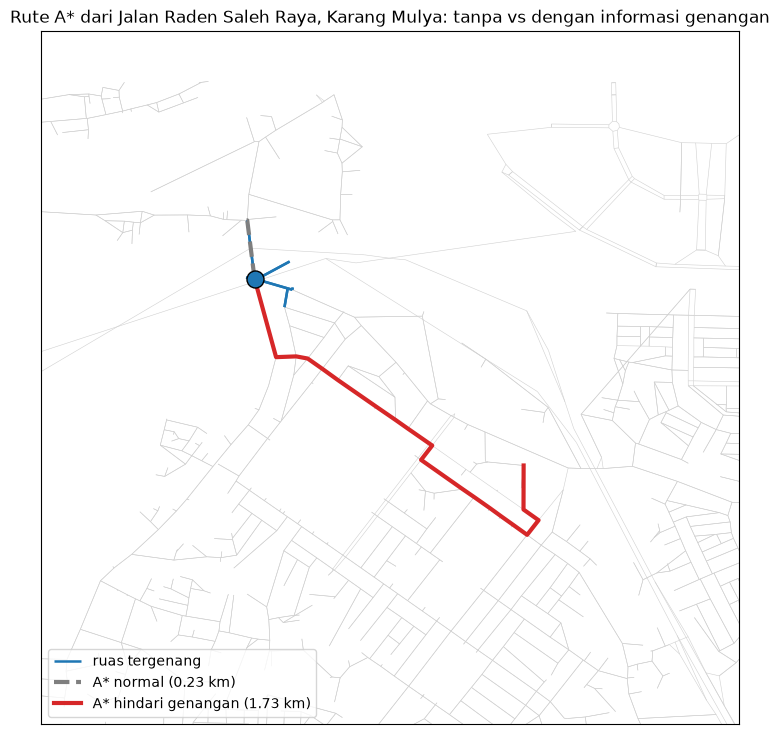

In [12]:
r_n, r_b = kasus["normal"]["A*"], kasus["banjir"]["A*"]
fig, ax = plt.subplots(figsize=(9, 9))
gambar_jalan(ax)
ax.plot([LON[n] for n in r_n.path], [LAT[n] for n in r_n.path], color="#7f7f7f", lw=3, ls="--", label=f"A* normal ({r_n.jarak_m/1000:.2f} km)")
ax.plot([LON[n] for n in r_b.path], [LAT[n] for n in r_b.path], color="#d62728", lw=3, label=f"A* hindari genangan ({r_b.jarak_m/1000:.2f} km)")
ax.scatter(LON[start], LAT[start], s=150, c="#1f77b4", edgecolor="k", zorder=4)
semua = r_n.path + r_b.path; pad = 0.006
ax.set_xlim(min(LON[n] for n in semua) - pad, max(LON[n] for n in semua) + pad)
ax.set_ylim(min(LAT[n] for n in semua) - pad, max(LAT[n] for n in semua) + pad)
ax.legend(loc="lower left"); ax.set_title(f"Rute A* dari {asal_kasus}: tanpa vs dengan informasi genangan"); ax.set_xticks([]); ax.set_yticks([])
plt.savefig(FIG / "03_astar_normal_vs_banjir.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Benchmark: 7 titik banjir × 2 skenario + 50 pasangan acak

In [13]:
runs = []
for b in banjir.itertuples():
    for sk in ["normal", "banjir"]:
        for nama, r in jalankan(int(b.node), sk == "banjir").items():
            runs.append(dict(asal=b.name, skenario=sk, algoritma=nama, origin_node=int(b.node), goal_node=int(r.path[-1]),
                             jarak_m=r.jarak_m, biaya=r.biaya, nodes_expanded=r.expanded, runtime_ms=r.runtime_ms,
                             path=[[round(LAT[n], 6), round(LON[n], 6)] for n in r.path]))
runs = pd.DataFrame(runs)
opt = runs[runs.algoritma == "UCS"].set_index(["asal", "skenario"]).biaya
runs["rasio_biaya_vs_optimal"] = runs.apply(lambda r: r.biaya / opt[(r.asal, r.skenario)], axis=1)
runs.groupby(["skenario", "algoritma"])[["jarak_m", "nodes_expanded", "runtime_ms", "rasio_biaya_vs_optimal"]].mean().round(2)

jarak_m  nodes_expanded  runtime_ms  \
skenario algoritma                                         
banjir   A*          1469.97          135.57        6.16   
         BFS         1278.50          621.43        0.28   
         DFS        10408.22          290.43        0.20   
         UCS         1469.97          554.71        0.67   
normal   A*          1145.91          161.00        7.20   
         BFS         1278.50          621.43        0.52   
         DFS        10408.22          290.43        0.28   
         UCS         1145.91          691.29        0.97   

                    rasio_biaya_vs_optimal  
skenario algoritma                          
banjir   A*                           1.00  
         BFS                          1.52  
         DFS                          5.88  
         UCS                          1.00  
normal   A*                           1.00  
         BFS                          1.09  
         DFS                         14.89  
         UCS                          1.00

In [14]:
acak = []
rng = random.Random(SEED)
for _ in range(50):
    s, t = rng.sample(nodes, 2)
    hs = {nama: f(s, {t}, True) for nama, f in ALGO.items()}
    for nama, r in hs.items():
        acak.append(dict(algoritma=nama, nodes_expanded=r.expanded, runtime_ms=r.runtime_ms,
                         rasio_biaya_vs_optimal=r.biaya / hs["UCS"].biaya))
acak = pd.DataFrame(acak)
ringkas = acak.groupby("algoritma").agg(node_expanded_rata2=("nodes_expanded", "mean"), runtime_ms_rata2=("runtime_ms", "mean"),
                                        rasio_biaya_rata2=("rasio_biaya_vs_optimal", "mean"),
                                        persen_optimal=("rasio_biaya_vs_optimal", lambda x: 100 * (x < 1 + 1e-9).mean()))
ringkas = ringkas.loc[["BFS", "DFS", "UCS", "A*"]].round(2)
ringkas

,node_expanded_rata2,runtime_ms_rata2,rasio_biaya_rata2,persen_optimal
algoritma,,,,
BFS,9556.24,5.94,1.30,2.0
DFS,9137.22,6.88,39.77,0.0
UCS,8748.48,12.73,1.00,100.0
A*,2546.54,7.05,1.00,100.0


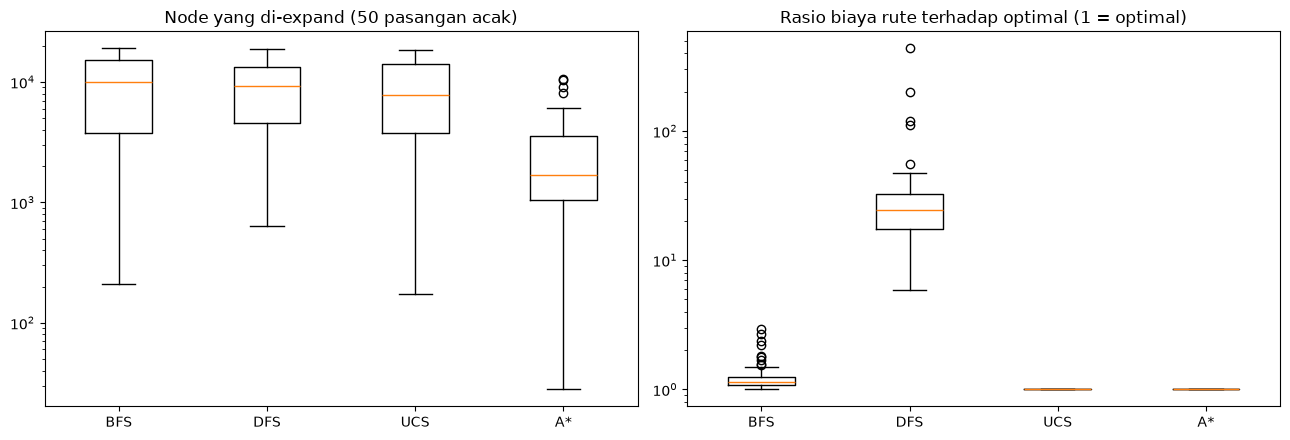

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
urutan = ["BFS", "DFS", "UCS", "A*"]
data = [acak[acak.algoritma == a].nodes_expanded for a in urutan]
ax[0].boxplot(data, tick_labels=urutan); ax[0].set_title("Node yang di-expand (50 pasangan acak)"); ax[0].set_yscale("log")
data = [acak[acak.algoritma == a].rasio_biaya_vs_optimal for a in urutan]
ax[1].boxplot(data, tick_labels=urutan); ax[1].set_title("Rasio biaya rute terhadap optimal (1 = optimal)"); ax[1].set_yscale("log")
plt.tight_layout(); plt.savefig(FIG / "03_benchmark.png", dpi=150); plt.show()

## 6. Kesimpulan (dicetak dari hasil)

In [16]:
a, u_, b_, d_ = (ringkas.loc[x] for x in ["A*", "UCS", "BFS", "DFS"])
print(f"- A* selalu optimal ({a.persen_optimal:.0f}% pasangan) dan rata-rata hanya meng-expand {a.node_expanded_rata2:.0f} node, "
      f"{u_.node_expanded_rata2 / a.node_expanded_rata2:.1f}× lebih sedikit dari UCS ({u_.node_expanded_rata2:.0f}).")
print(f"- BFS optimal pada {b_.persen_optimal:.0f}% pasangan; rata-rata biaya {b_.rasio_biaya_rata2:.2f}× optimal karena mengabaikan panjang ruas dan genangan.")
print(f"- DFS optimal pada {d_.persen_optimal:.0f}% pasangan; rata-rata biaya {d_.rasio_biaya_rata2:.2f}× optimal (rute berputar-putar).")
rb = runs[(runs.algoritma == "A*")].pivot(index="asal", columns="skenario", values="jarak_m")
print(f"- Menghindari genangan menambah jarak A* rata-rata {(rb.banjir - rb.normal).mean():.0f} m dari 7 titik laporan.")

- A* selalu optimal (100% pasangan) dan rata-rata hanya meng-expand 2547 node, 3.4× lebih sedikit dari UCS (8748).
- BFS optimal pada 2% pasangan; rata-rata biaya 1.30× optimal karena mengabaikan panjang ruas dan genangan.
- DFS optimal pada 0% pasangan; rata-rata biaya 39.77× optimal (rute berputar-putar).
- Menghindari genangan menambah jarak A* rata-rata 324 m dari 7 titik laporan.


## 7. Ekspor untuk web dan simpan ke Supabase

In [17]:
idx = {n: i for i, n in enumerate(adj)}
graf_json = {
    "center": PUSAT, "penalti": PENALTI,
    # tanpa pembulatan: pembulatan sekecil 0,1 m sudah mengubah urutan expand A* sehingga web tidak identik dengan notebook
    "nodes": [[LAT[n], LON[n]] for n in adj],
    "edges": [[idx[u], idx[v], L, int(f)] for u, nbs in adj.items() for v, L, f in nbs],
    "safe_places": [{"node": idx[int(r.node)], "name": r.name, "kind": r.kind, "lat": r.lat, "lon": r.lon} for r in aman.itertuples()],
    "flood_points": [{"node": idx[int(r.node)], "name": r.name, "lat": r.lat, "lon": r.lon, "radius_m": int(r.radius_m),
                      "source_url": r.source_url} for r in banjir.itertuples()],
}
(EXPORT / "graph_ciledug.json").write_text(json.dumps(graf_json, separators=(",", ":"), ensure_ascii=False), encoding="utf8")
print("graph_ciledug.json:", round((EXPORT / "graph_ciledug.json").stat().st_size / 1024), "KB")

graph_ciledug.json: 1878 KB


In [18]:
db_url = os.environ.get("SUPABASE_DB_URL")
if "google.colab" in sys.modules and not db_url:
    try:
        from google.colab import userdata
        db_url = userdata.get("SUPABASE_DB_URL")
    except Exception as e:  # tampilkan alasan (mis. Notebook access belum diizinkan)
        print(f"Gagal membaca secret: {type(e).__name__}: {e}")
        db_url = None

if not db_url:
    print("SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.")
else:
    import psycopg2
    from psycopg2.extras import execute_values, Json
    with psycopg2.connect(db_url) as conn, conn.cursor() as cur:
        cur.execute("truncate uts_ai_bencana.safe_places, uts_ai_bencana.flood_points, uts_ai_bencana.search_runs restart identity")
        execute_values(cur, "insert into uts_ai_bencana.safe_places (id, name, kind, lat, lon) values %s",
                       [(int(r.osmid), r.name, r.kind, float(r.lat), float(r.lon)) for r in aman.itertuples()])
        execute_values(cur, "insert into uts_ai_bencana.flood_points (name, lat, lon, radius_m, source_url) values %s",
                       [(r.name, float(r.lat), float(r.lon), float(r.radius_m), r.source_url) for r in banjir.itertuples()])
        execute_values(cur, """insert into uts_ai_bencana.search_runs (scenario, algorithm, origin_node, goal_node, path_length_m,
                       nodes_expanded, runtime_ms, path) values %s""",
                       [(r.skenario, r.algoritma, int(r.origin_node), int(r.goal_node), float(r.jarak_m), int(r.nodes_expanded),
                         float(r.runtime_ms), Json(r.path)) for r in runs.itertuples()])
    print(f"✓ Tersimpan: {len(aman)} tempat aman, {len(banjir)} titik banjir, {len(runs)} hasil pencarian")

SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.
